# Practice 2 — Intel Image Classification / Local XPU
Chạy từ trên xuống, kernel **Lab2 (.venv)**. Source nằm trong `src/phases/`; notebook chỉ điều phối.
WF-001 đã có benchmark riêng trong `outputs/environment/main.executed.ipynb`. WF-002 dưới đây dùng dữ liệu thật.
Restart kernel sau khi sửa source. Không chạy training CLI song song notebook.


In [1]:
from pathlib import Path
import sys, inspect, json
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'configs/experiments.json').exists(), 'Open notebook from D:/Lab2'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.phases import phase_02_data, phase_03_models, phase_04_train, phase_05_evaluate
from IPython.display import display, Markdown, Image
PHASES = {2: phase_02_data, 3: phase_03_models, 4: phase_04_train, 5: phase_05_evaluate}
print('Python:', sys.executable)
print('Workspace:', ROOT)
print((ROOT / 'configs/experiments.json').read_text(encoding='utf-8'))


Python: D:\Lab2\.venv\Scripts\python.exe
Workspace: D:\Lab2
{
  "workflow": "WF-002-v1.0",
  "seed": 42,
  "device": "xpu",
  "data_version": 2,
  "validation_fraction": 0.2,
  "num_workers": 0,
  "runs": [
    {"id":"R01","model":"vgg11","mode":"transfer","lr":0.001,"batch":8,"epochs":5},
    {"id":"R02","model":"vgg11","mode":"transfer","lr":0.0003,"batch":8,"epochs":5},
    {"id":"R03","model":"vgg11","mode":"transfer","lr":0.001,"batch":16,"epochs":5},
    {"id":"R04","model":"densenet121","mode":"transfer","lr":0.001,"batch":8,"epochs":5},
    {"id":"R05","model":"densenet121","mode":"transfer","lr":0.0003,"batch":8,"epochs":5},
    {"id":"R06","model":"densenet121","mode":"transfer","lr":0.001,"batch":16,"epochs":5}
  ],
  "fine_tune":{"id":"R07","mode":"finetune","lr":0.00001,"epochs":3}
}



## Chọn phạm vi
`START_PHASE = END_PHASE` để chạy một phase; chọn 2–5 để chạy hết. Prerequisite phải tồn tại.
Phase 02 kiểm tra manifest; phase 03 kiểm chứng GPU; phase 04 train/resume hoặc xác minh run hoàn tất; phase 05 đánh giá test hoặc đọc kết quả test đã lưu.


In [2]:
START_PHASE, END_PHASE = 2, 5
assert 2 <= START_PHASE <= END_PHASE <= 5
for number in range(START_PHASE, END_PHASE + 1):
    module = PHASES[number]
    print(f'PHASE-{number:02d}: {inspect.getfile(module)}')
    print(inspect.getsource(module.run))


PHASE-02: D:\Lab2\src\phases\phase_02_data.py
def run():
    OUT.mkdir(parents=True, exist_ok=True)
    if (OUT / 'audit.json').exists():
        audit = read_json(OUT / 'audit.json')
        if audit['manifest_sha256'] != sha256(MANIFEST):
            raise ValueError('Manifest changed since audit')
        return audit
    archive = ROOT / 'data/downloads/intel-v2.zip'
    url = 'https://www.kaggle.com/api/v1/datasets/download/puneet6060/intel-image-classification?datasetVersionNumber=2'
    download(url, archive)
    if not zipfile.is_zipfile(archive):
        raise ValueError('Kaggle response is not a ZIP archive')
    marker = ROOT / 'data/raw/intel-v2.extracted.json'
    if not RAW.exists():
        safe_extract(archive, RAW)
        write_json(marker, {'archive_sha256': sha256(archive)})
    if not marker.exists() or read_json(marker)['archive_sha256'] != sha256(archive):
        raise ValueError('Raw extraction incomplete or archive changed')
    train = inspect_images(locate('

In [3]:
phase_results = {}
for number in range(START_PHASE, END_PHASE + 1):
    print(f'Running PHASE-{number:02d}', flush=True)
    phase_results[number] = PHASES[number].run()
    print(f'PHASE-{number:02d} finished', flush=True)


Running PHASE-02


PHASE-02 finished


Running PHASE-03


PHASE-03 finished


Running PHASE-04


...

R06: verified completed run


R07: verified completed run


PHASE-04 finished


Running PHASE-05


PHASE-05 finished


# Practice 2 — Pretrained neural networks: Intel Image Classification

Hoàn tất: 2026-10-30T08:10:54.217819+00:00. Thiết bị của toàn bộ ma trận: **xpu**.

## Dữ liệu và phương pháp

Dataset Kaggle Intel Image Classification v2: 14034 ảnh train gốc, 3000 ảnh test và 7301 ảnh chưa gán nhãn (không dùng chấm điểm).
Sau kiểm tra SHA256/nhãn: train **11208**, validation **2798**, test **3000**. Loại 28 bản ghi train do trùng, chồng lấn test hoặc nhãn mâu thuẫn; không sửa dữ liệu gốc.
13 nhóm ảnh có nhãn mâu thuẫn: cách ly 23 ảnh train; giữ nguyên test. Xem `../data/label_conflicts.json` và amendment 01. Train/validation/test không giao SHA256. Chia phân tầng seed 42, validation 20% làm tròn xuống theo lớp.
Ảnh RGB được resize cạnh ngắn 256, crop 224 và chuẩn hóa ImageNet. Train dùng random crop/flip; validation/test dùng center crop. Adam, float32, num_workers=0, không bỏ batch cuối.
Trọng số ImageNet1K_V1 của torchvision; thay đầu ra bằng 6 lớp. Transfer chỉ cập nhật linear cuối. Fine-tune mở block cuối cùng và linear cuối. Giữ dropout/BatchNorm ở eval trong mọi run để backbone cố định đúng nghĩa; affine của BN trong block mở vẫn nhận gradient.
R01–R06: 5 epoch từ cùng weights và seed 42; mỗi cặp LR/batch chỉ thay một yếu tố. R07: 3 epoch bổ sung từ checkpoint validation tốt nhất, Adam mới lr 1e-5. Lựa chọn theo accuracy validation giảm dần, rồi loss, epoch và run ID tăng dần.

## Kiến trúc

| Model / mode | Tổng tham số | Trainable |
|---|---:|---:|
| vgg11 / transfer | 128,790,918 | 24,582 |
| vgg11 / finetune | 128,790,918 | 4,744,198 |
| densenet121 / transfer | 6,960,006 | 6,150 |
| densenet121 / finetune | 6,960,006 | 2,166,278 |

Cấu trúc đầy đủ và tên các tham số trainable: `../models/`.

## Thí nghiệm validation

| Run | Model | Mode | LR | Batch | Best epoch | Val accuracy | Val loss | Phút train+val |
|---|---|---|---:|---:|---:|---:|---:|---:|
| R01 | vgg11 | transfer | 0.001 | 8 | 5 | 90.99% | 0.3007 | 19.5 |
| R02 | vgg11 | transfer | 0.0003 | 8 | 5 | 91.53% | 0.2359 | 18.0 |
| R03 | vgg11 | transfer | 0.001 | 16 | 5 | 91.24% | 0.2626 | 16.6 |
| R04 | densenet121 | transfer | 0.001 | 8 | 2 | 91.03% | 0.2299 | 17.7 |
| R05 | densenet121 | transfer | 0.0003 | 8 | 5 | 91.10% | 0.2313 | 19.5 |
| R06 | densenet121 | transfer | 0.001 | 16 | 3 | 91.21% | 0.2367 | 16.7 |
| R07 | vgg11 | finetune | 1e-05 | 8 | 3 | 92.03% | 0.2494 | 14.3 |


## Nhận xét từ số đo

- vgg11: giảm LR 0.001 → 0.0003 thay đổi validation accuracy +0.54 điểm phần trăm; tăng batch 8 → 16 thay đổi +0.25 điểm phần trăm (so với R01).
- densenet121: giảm LR 0.001 → 0.0003 thay đổi validation accuracy +0.07 điểm phần trăm; tăng batch 8 → 16 thay đổi +0.18 điểm phần trăm (so với R04).
- Fine-tune R07 so với checkpoint cha R02: +0.50 điểm phần trăm validation. R07 có thêm ngân sách 3 epoch nên đây không phải so sánh ngang ngân sách.
- Model cuối được chốt bằng validation trước khi test: **R07**; best transfer: **R02**.

## Đánh giá test sau khi khóa lựa chọn

| Run | Test accuracy | Macro-F1 | Loss | Số ảnh |
|---|---:|---:|---:|---:|
| R02 | 91.70% | 0.9186 | 0.2132 | 3000 |
| R06 | 91.53% | 0.9168 | 0.2230 | 3000 |
| R07 | 92.80% | 0.9297 | 0.2033 | 3000 |




Precision, recall, F1 và support từng lớp trong `per_class_metrics.csv`; zero division = 0. Dự đoán từng ảnh nằm trong các file `*_predictions.csv`.

## Giới hạn và khả năng tái lập

- Chỉ một seed, chưa đo độ biến thiên qua nhiều lần chạy. Không suy rộng chênh lệch nhỏ thành kết luận thống kê.
- Dataset có nhãn mơ hồ và ảnh trùng. SHA256 chỉ phát hiện trùng byte, không phát hiện tất cả ảnh gần giống.
- Thời gian đo trên laptop Intel Arc dùng bộ nhớ chung; chịu ảnh hưởng nhiệt độ và tiến trình khác. Thời gian trong bảng chỉ gồm vòng train/validation, không gồm tải, khởi tạo hay ghi checkpoint.
- XPU không được cam kết tái lập bitwise. Checkpoint lưu RNG, optimizer, config, source/data/dependency hashes để resume cùng môi trường.
- Test không dùng điều chỉnh siêu tham số; model cuối không chọn theo test accuracy.

## Artifacts

`experiments.csv`, `epoch_metrics.csv`, `test_metrics.csv`, `per_class_metrics.csv`, `summary.json`; checkpoint/TensorBoard/identity theo từng run trong `../experiments/`.
Nguồn dataset: https://www.kaggle.com/datasets/puneet6060/intel-image-classification/data. Weight provenance: `../models/weights.json`.

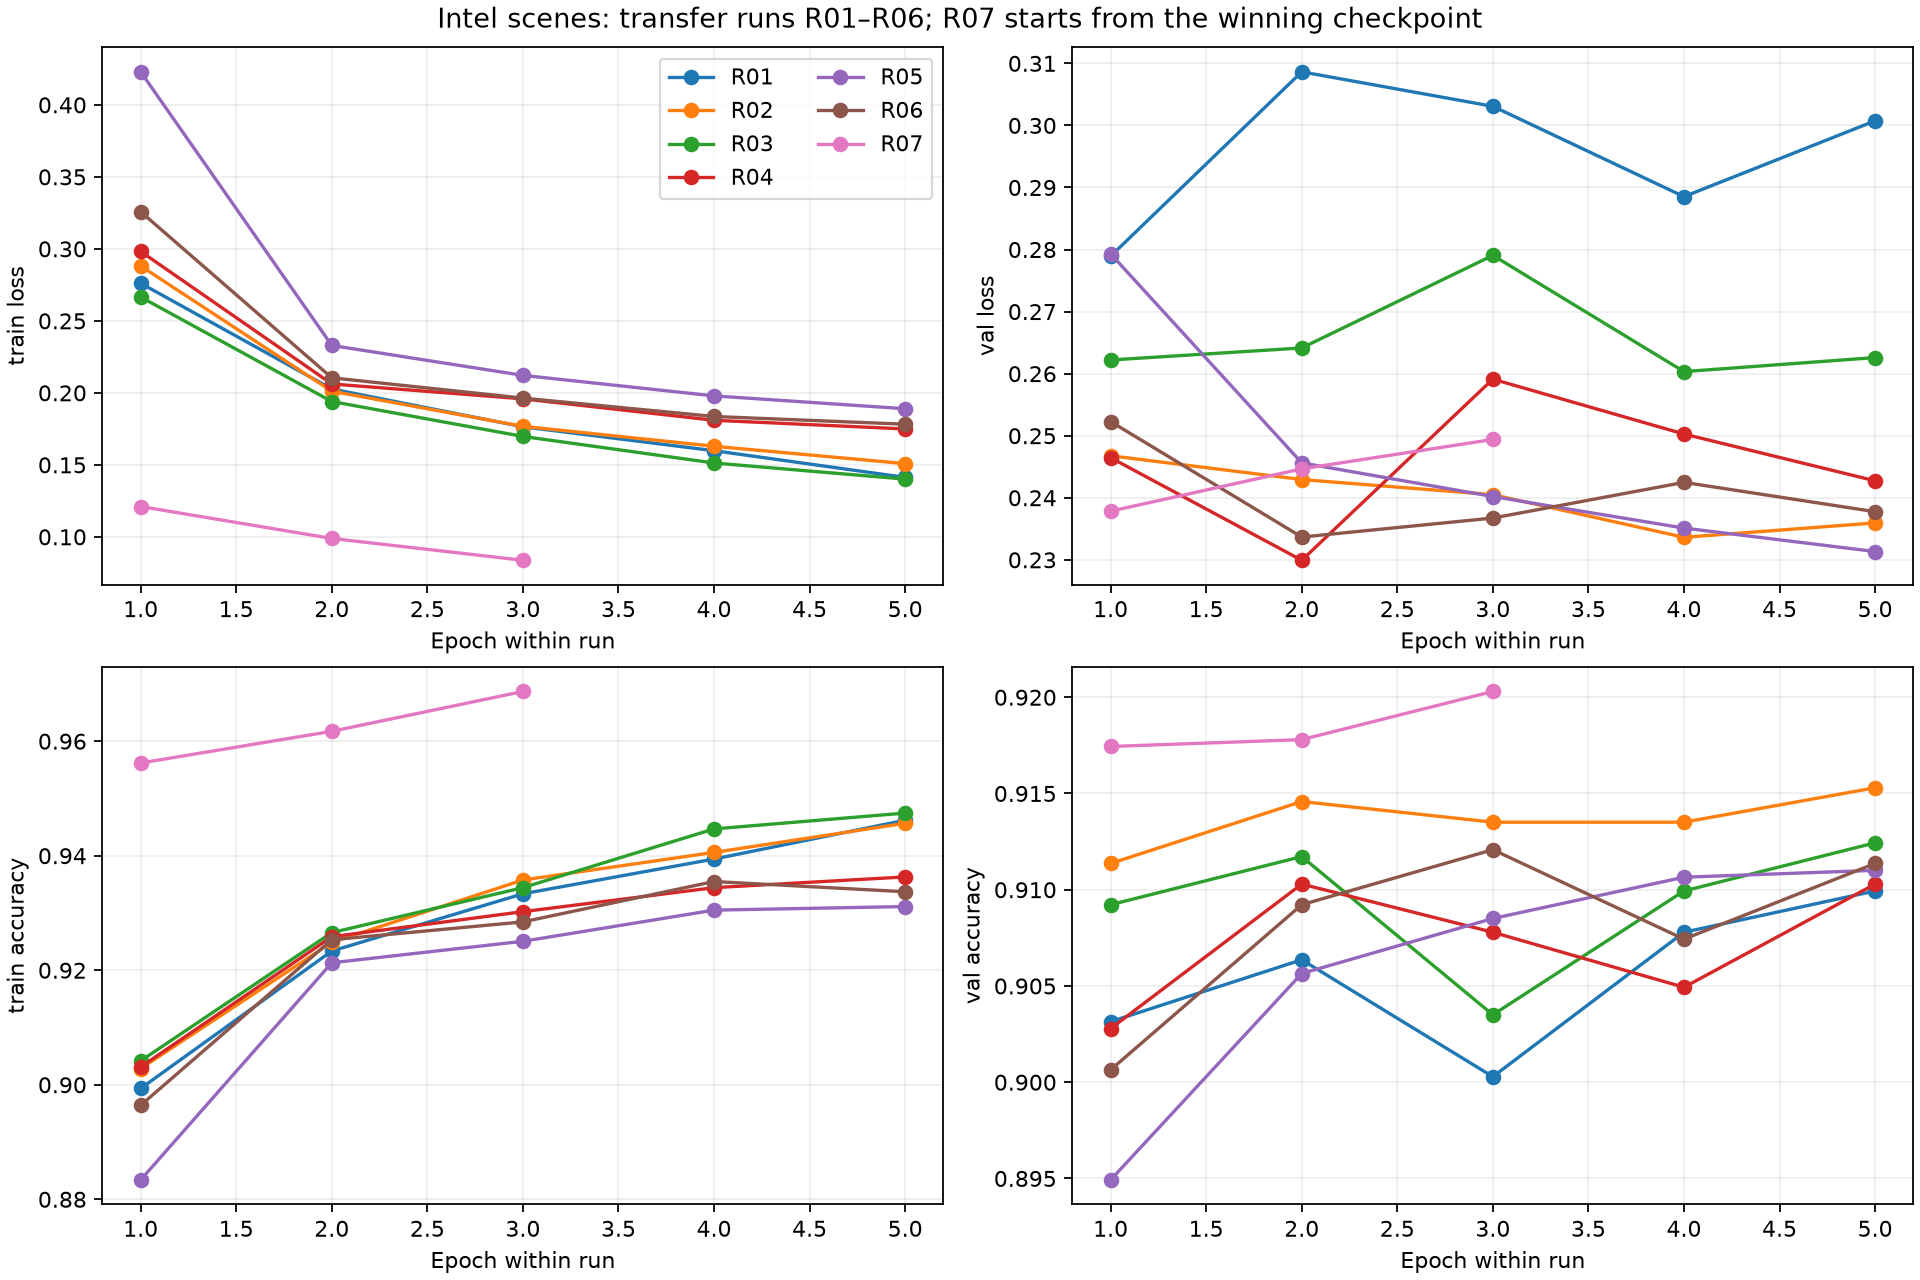

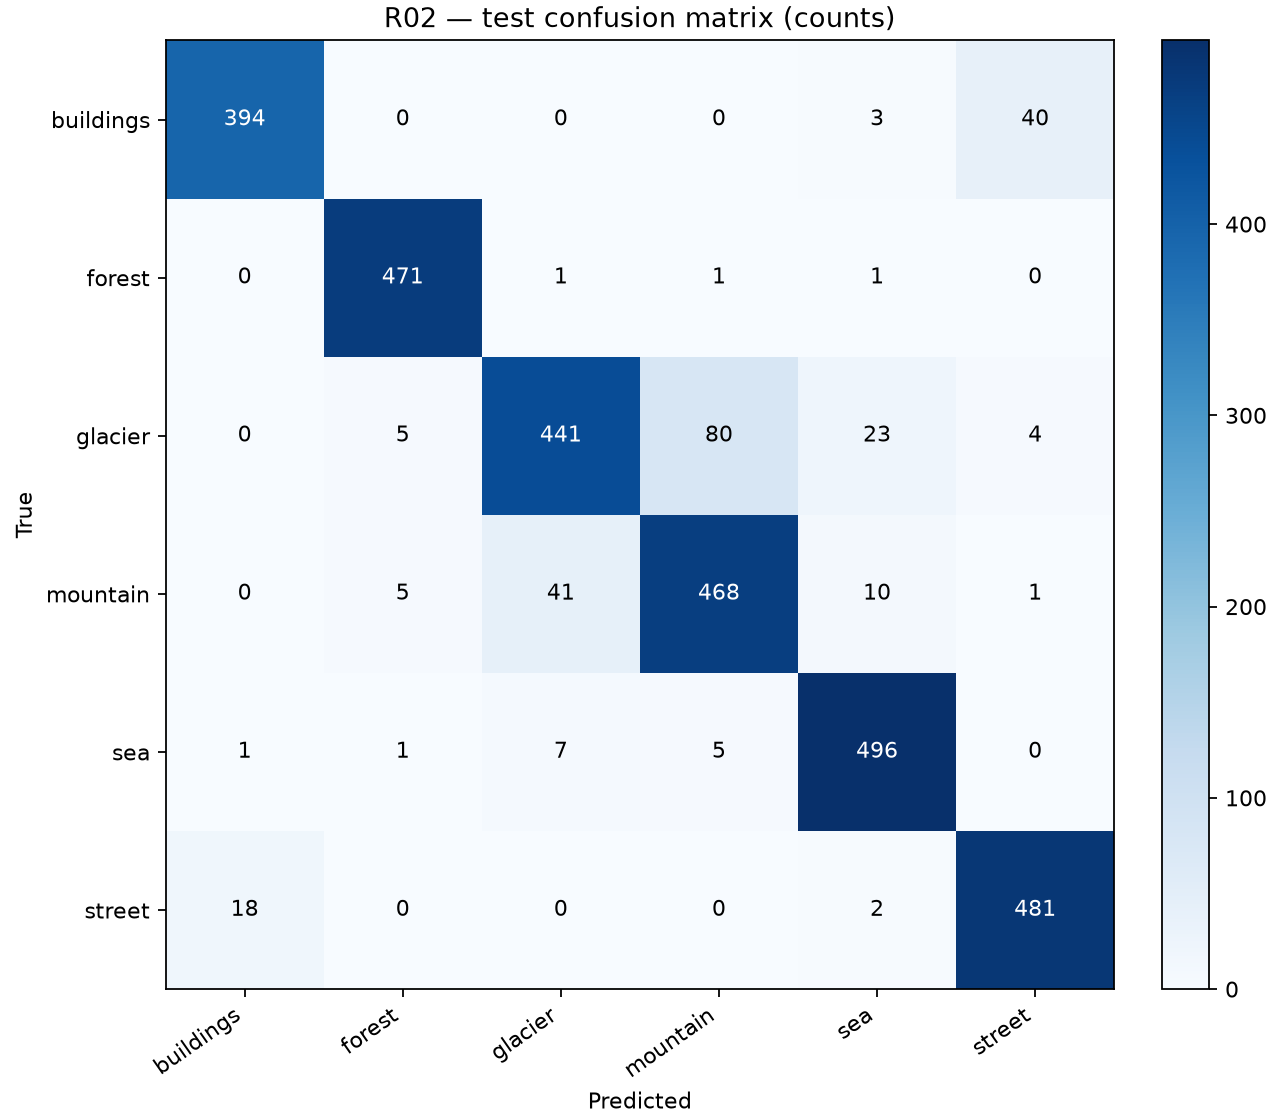

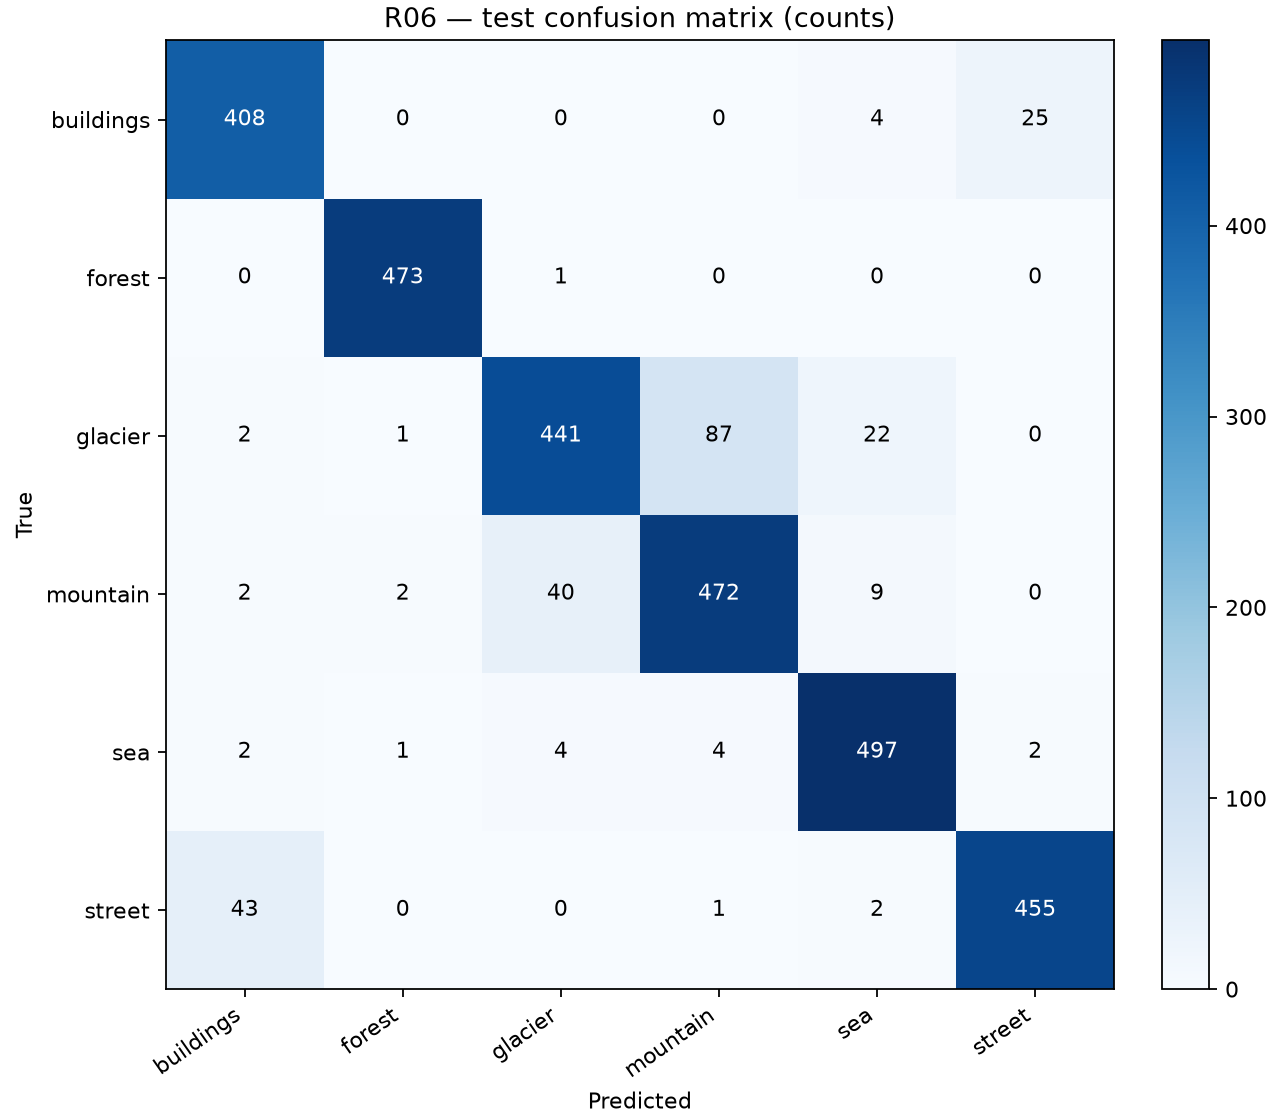

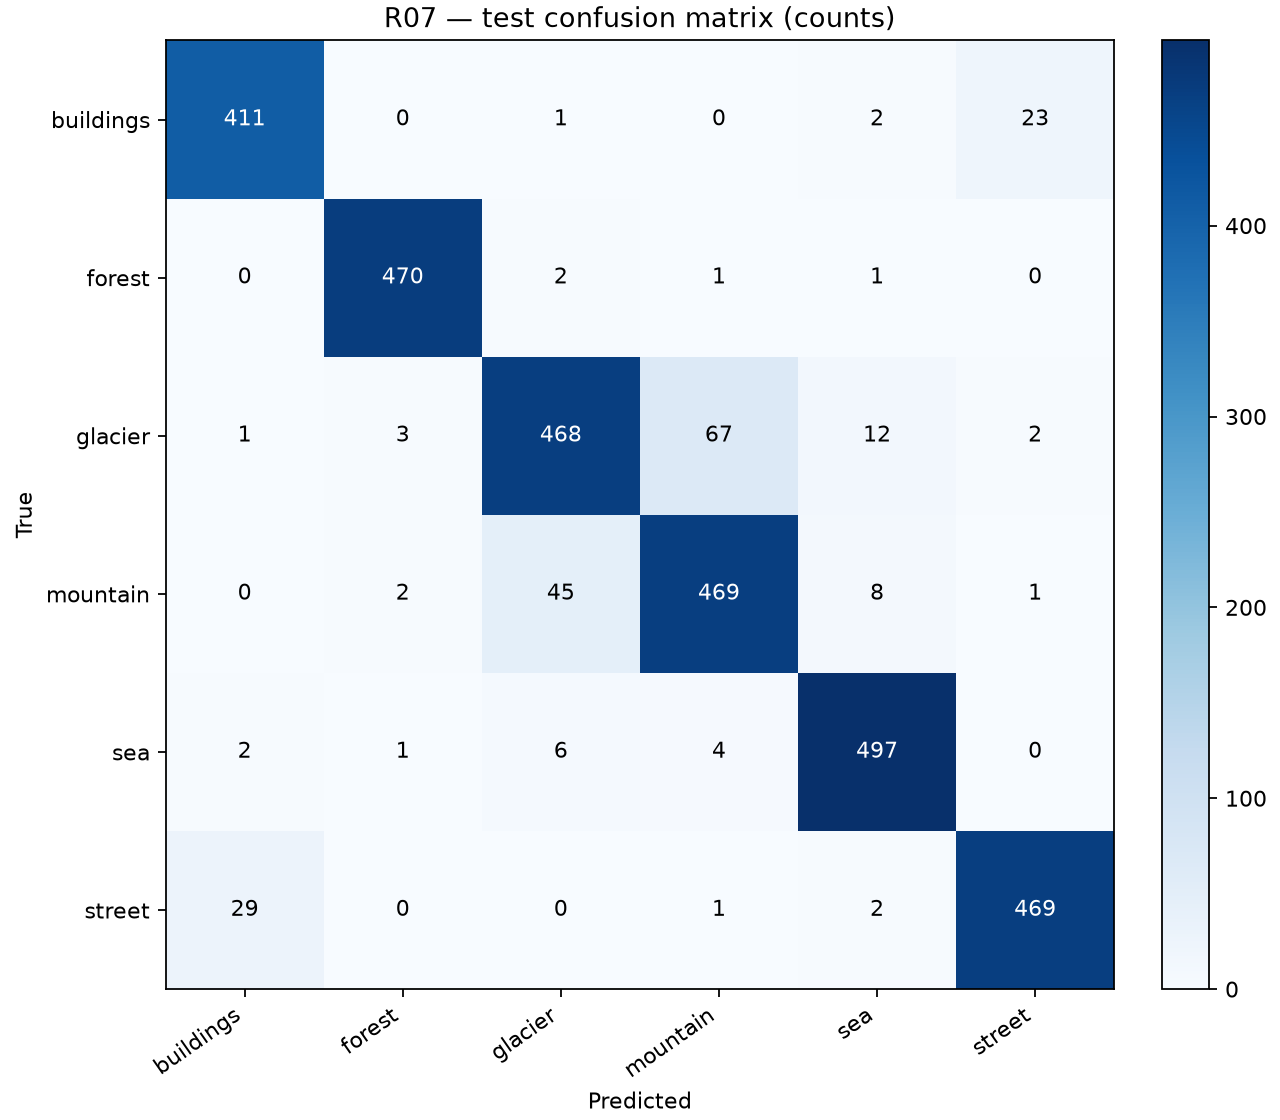

In [4]:
report = ROOT / 'outputs/report/report.md'
if report.exists() and 5 in phase_results:
    display(Markdown('\n'.join(line for line in report.read_text(encoding='utf-8').splitlines() if not line.startswith('!['))))
    display(Image(filename=str(ROOT / 'outputs/report/learning_curves.png')))
    for run_id in phase_results[5]['selection']['test_runs']:
        display(Image(filename=str(ROOT / f'outputs/report/{run_id}_confusion_matrix.png')))
else:
    print('Partial pipeline: report is not presented as newly verified.')


In [5]:
print('TensorBoard (run in a separate PowerShell terminal at D:/Lab2):')
print(r'.\.venv\Scripts\python.exe -m tensorboard.main --logdir outputs/experiments --host 127.0.0.1 --port 6006')
print('http://127.0.0.1:6006')


TensorBoard (run in a separate PowerShell terminal at D:/Lab2):
.\.venv\Scripts\python.exe -m tensorboard.main --logdir outputs/experiments --host 127.0.0.1 --port 6006
http://127.0.0.1:6006
